<a href="https://colab.research.google.com/github/xuannn0212/lepidoptera-benchmark-analysis/blob/main/P2_ResNet50_Benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

os.environ['KAGGLE_USERNAME'] = ""
os.environ['KAGGLE_KEY'] = ""  # Paste your Kaggle key here

print("Kaggle credentials successfully configured!")

Kaggle credentials successfully configured!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!kaggle datasets download -d gpiosenka/butterfly-images40-species

Dataset URL: https://www.kaggle.com/datasets/gpiosenka/butterfly-images40-species
License(s): CC0-1.0
100% 399M/399M [00:19<00:00, 22.0MB/s]



In [ ]:
import zipfile
import shutil
import os

print("Cleaning up failed run...")
if os.path.exists('master_dataset'):
    shutil.rmtree('master_dataset')
if os.path.exists('raw_dataset'):
    shutil.rmtree('raw_dataset')

print("Re-extracting fresh dataset...")
zip_ref = zipfile.ZipFile('butterfly-images40-species.zip', 'r')
zip_ref.extractall('raw_dataset')
zip_ref.close()

master_dir = 'master_dataset'
os.makedirs(master_dir, exist_ok=True)

def merge_folders(source_dir, prefix):
    if os.path.exists(source_dir):
        for species_folder in os.listdir(source_dir):
            src_path = os.path.join(source_dir, species_folder)
            dest_path = os.path.join(master_dir, species_folder)

            if not os.path.exists(dest_path):
                os.makedirs(dest_path)

            for img_file in os.listdir(src_path):
                new_filename = f"{prefix}_{img_file}"
                shutil.move(os.path.join(src_path, img_file), os.path.join(dest_path, new_filename))

print("Merging and renaming files to prevent collisions...")
merge_folders('raw_dataset/train', 'train')
merge_folders('raw_dataset/valid', 'valid')
merge_folders('raw_dataset/test', 'test')

print("All images successfully merged into a single master folder!")

Cleaning up failed run...
Re-extracting fresh dataset...
Merging and renaming files to prevent collisions...
All images successfully merged into a single master folder!


In [ ]:
!pip install split-folders

import splitfolders

# CHANGED: Use Colab's local storage instead of Google Drive for the dataset
output_local_path = '/content/Dataset'

print("Executing strict 70/15/15 dataset split locally...")
splitfolders.ratio('master_dataset',
                   output=output_local_path,
                   seed=42,
                   ratio=(.7, .15, .15),
                   group_prefix=None,
                   move=False)

print(f"Split complete! Dataset saved locally at: {output_local_path}")

Executing strict 70/15/15 dataset split locally...


Copying files: 13594 files [00:02, 5557.03 files/s]

Split complete! Dataset saved locally at: /content/Dataset


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.random.set_seed(42)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 100

# CHANGED: Read from the local Colab SSD to feed the GPU instantly
TRAIN_DIR = '/content/Dataset/train'
VAL_DIR = '/content/Dataset/val'
TEST_DIR = '/content/Dataset/test'

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    seed=42
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    seed=42
)

Found 9473 images belonging to 100 classes.
Found 1986 images belonging to 100 classes.


In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

EPOCHS_STAGE1 = 15
checkpoint_path = "/content/drive/MyDrive/P2_ResNet50_Best_Model.keras"

# Build ResNet-50 Architecture
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Initially freeze all base model layers
base_model.trainable = False

# Construct Classification Head with Dropout for Regularization
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

print("--- STAGE 1: Training Classification Head ---")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage1 = [
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
]

history1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
--- STAGE 1: Training Classification Head ---
Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - accuracy: 0.3759 - loss: 2.9569
Epoch 1: val_accuracy improved from None to 0.85700, saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 185s 574ms/step - accuracy: 0.5947 - loss: 1.7465 - val_accuracy: 0.8570 - val_loss: 0.5847
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.8507 - loss: 0.5799
Epoch 2: val_accuracy improved from 0.85700 to 0.88922, saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 143s 481ms/step - accuracy: 0.8546 - loss: 0.5581 - val_accuracy: 0.8892 - val_loss: 0.4112
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

EPOCHS_STAGE2 = 35

print("--- STAGE 2: Fine-Tuning ResNet-50 Base Layers ---")

# Unfreeze entire model to access layers
base_model.trainable = True

# Freeze lower layers up to conv5 block (layer index 140)
fine_tune_at = 140
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile with a low learning rate to preserve pre-trained features
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage2 = [
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)
]

history2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2
)

--- STAGE 2: Fine-Tuning ResNet-50 Base Layers ---
Epoch 1/35
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.9033 - loss: 0.3141
Epoch 1: val_accuracy improved from None to 0.91893, saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 186s 549ms/step - accuracy: 0.9242 - loss: 0.2479 - val_accuracy: 0.9189 - val_loss: 0.3337 - learning_rate: 1.0000e-05
Epoch 2/35
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - accuracy: 0.9595 - loss: 0.1409
Epoch 2: val_accuracy improved from 0.91893 to 0.92548, saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/P2_ResNet50_Best_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 150s 505ms/step - accuracy: 0.9596 - loss: 0.1380 - val_accuracy: 0.9255 - val_loss: 0.3078 - learning_rate: 1.0000e-05
Epoch 3/35
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - 

In [ ]:
import numpy as np
import time
from sklearn.metrics import classification_report
from tensorflow.keras.models import load_model

print("Loading best model weights...")
best_model = load_model(checkpoint_path)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\nEvaluating model on unseen test data...")
# 1. Start the timer right before prediction
start_time = time.time()

# 2. Run the prediction
predictions = best_model.predict(test_generator)

# 3. Stop the timer the exact millisecond it finishes
end_time = time.time()

# 4. Calculate and print the speed metrics
total_time = end_time - start_time
print(f"\n--- INFERENCE SPEED BENCHMARK ---")
print(f"Total Inference Time (2,135 images): {total_time:.2f} seconds")
print(f"Average Time per Image: {(total_time / 2135) * 1000:.2f} milliseconds")

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

print("\n--- MACRO METRICS & CLASSIFICATION REPORT ---")
print(classification_report(y_true, y_pred, target_names=list(test_generator.class_indices.keys())))

Loading best model weights...
Found 2135 images belonging to 100 classes.

Evaluating model on unseen test data...
67/67 ━━━━━━━━━━━━━━━━━━━━ 17s 187ms/step

--- INFERENCE SPEED BENCHMARK ---
Total Inference Time (2,135 images): 17.06 seconds
Average Time per Image: 7.99 milliseconds

--- MACRO METRICS & CLASSIFICATION REPORT ---
                           precision    recall  f1-score   support

                   ADONIS       0.95      0.90      0.93        21
AFRICAN GIANT SWALLOWTAIL       1.00      1.00      1.00        19
           AMERICAN SNOOT       0.95      1.00      0.97        18
                    AN 88       1.00      1.00      1.00        21
                  APPOLLO       1.00      0.91      0.95        22
     ARCIGERA FLOWER MOTH       1.00      0.91      0.95        23
                    ATALA       1.00      1.00      1.00        24
               ATLAS MOTH       0.84      0.95      0.89        22
 BANDED ORANGE HELICONIAN       0.96      0.96      0.96        

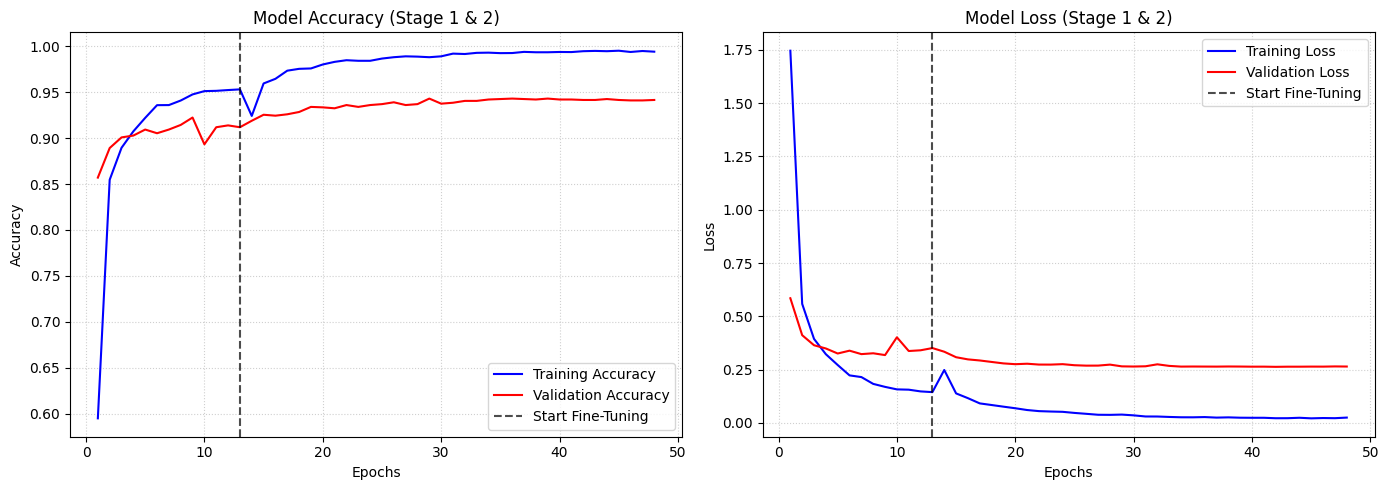

In [ ]:
import matplotlib.pyplot as plt

# 1. Combine the history data from Stage 1 and Stage 2
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

# 2. Set up the epochs timeline
epochs = range(1, len(acc) + 1)
stage1_epochs = len(history1.history['accuracy'])

# 3. Create a wide figure to hold two side-by-side graphs
plt.figure(figsize=(14, 5))

# --- GRAPH 1: ACCURACY ---
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'b-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
# Add a vertical dotted line to show where Fine-Tuning started
plt.axvline(x=stage1_epochs, color='k', linestyle='--', alpha=0.7, label='Start Fine-Tuning')
plt.title('Model Accuracy (Stage 1 & 2)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# --- GRAPH 2: LOSS ---
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'b-', label='Training Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
# Add a vertical dotted line to show where Fine-Tuning started
plt.axvline(x=stage1_epochs, color='k', linestyle='--', alpha=0.7, label='Start Fine-Tuning')
plt.title('Model Loss (Stage 1 & 2)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# 4. Display the graphs
plt.tight_layout()
plt.show()